# 03 · Fusée et plume : du baril à la pompe

Les automobilistes en sont persuadés : quand le pétrole flambe, les prix à la pompe montent aussitôt, et quand il baisse, ils prennent leur temps. Les économistes appellent cela l'effet **« fusée et plume »** (*rockets and feathers*). Ce notebook le mesure sur vingt ans de données françaises.

**Questions**
1. De quoi est fait le prix d'un litre de gazole, et qu'est-ce qui l'a fait grimper en 2026 ?
2. La part qui revient au raffinage et à la distribution a-t-elle changé ?
3. Les prix montent-ils plus vite qu'ils ne baissent quand le Brent varie ?
4. Que s'est-il passé pendant la crise de 2026 ?

**Données**
- **Bulletin pétrolier européen** (Commission européenne, CC BY 4.0) : prix moyens hebdomadaires en France, avec et sans taxes, chaque lundi depuis 2005.
- **Brent daté** et **taux euro/dollar** (FRED, Réserve fédérale de Saint-Louis), quotidiens, convertis en euros par litre (159 litres par baril).
- L'historique des prix des stations (notebook 02), pour vérifier que le bulletin décrit bien les mêmes pompes.

Les deux premières sources sont collectées par le workflow quotidien sur la branche `data` (dossier `marches/`). Prix en **euros courants**. Les chiffres cités dans le texte sont recalculés et vérifiés par la dernière cellule.

In [1]:
from datetime import date
import json
import subprocess
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from carburants import analyse, marches, transmission

DONNEES = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
chiffres = {}

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def axe_annees(ax, pas=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(pas))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

commit = subprocess.run(["git", "-C", str(DONNEES), "log", "-1", "--format=%h %ci"], capture_output=True, text=True).stdout.strip()
print("Branche data au commit :", commit or "inconnu")
print("Bulletin :", (DONNEES / "marches/bulletin_petrolier/source.txt").read_text().strip())

Branche data au commit : b3ec596 2026-10-19 14:28:46 +0000
Bulletin : https://energy.ec.europa.eu/document/download/906e60ca-8b6a-44e7-8589-652854d2fd3f_en?filename=Weekly_Oil_Bulletin_Prices_History_maticni_4web.xlsx


## Les données

Le bulletin donne, chaque lundi, le prix moyen national du gazole et du sans-plomb 95 avec et sans taxes. On lui associe le cours moyen du Brent sur les sept jours qui précèdent, en euros par litre.

Une correction s'impose pour 2022 : la **remise carburant de l'État** (18 centimes TTC d'avril à août, 30 en septembre et octobre, 10 en novembre et décembre) est déduite des prix du bulletin. On la rajoute au prix hors taxes pour mesurer ce que facture la filière. La remise propre à TotalEnergies (septembre à décembre 2022) n'est pas corrigée : c'est un choix commercial, qui fait partie de la marge.

In [2]:
bulletin = marches.lire_bulletin((DONNEES / "marches/bulletin_petrolier/historique_prix.xlsx").read_bytes())
brent = transmission.brent_hebdo(pl.read_parquet(DONNEES / "marches/brent_change.parquet"))
hebdo = (
    bulletin.join(brent, on="date", how="inner")
    .with_columns(remise=transmission.remise_etat())
    .with_columns(
        marge_gazole=pl.col("gazole_ht") + pl.col("remise") - pl.col("brent_eur_litre"),
        marge_sp95=pl.col("sp95_ht") + pl.col("remise") - pl.col("brent_eur_litre"),
        taxes_gazole=pl.col("gazole_ttc") - pl.col("gazole_ht"),
    )
)
semaines_attendues = (hebdo["date"].max() - hebdo["date"].min()).days // 7 + 1
chiffres["semaines"], chiffres["semaines_manquantes"] = hebdo.height, semaines_attendues - hebdo.height
print(f"{hebdo.height} semaines du {hebdo['date'].min()} au {hebdo['date'].max()} ({semaines_attendues - hebdo.height} semaines sans bulletin)")
hebdo.tail(3)

1088 semaines du 2005-01-03 au 2026-10-12 (49 semaines sans bulletin)


date,sp95_ht,sp95_ttc,gazole_ht,gazole_ttc,brent_usd_baril,brent_eur_litre,jours,remise,marge_gazole,marge_sp95,taxes_gazole
date,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64
2026-09-28,1.153783,2.21278,1.368025,2.37063,117.084,0.645257,5,0.0,0.722768,0.508526,1.002605
2026-10-05,1.152892,2.21171,1.3554,2.35548,120.034,0.667756,5,0.0,0.687644,0.485135,1.00008
2026-10-12,1.153317,2.21222,1.332708,2.32825,127.432,0.715093,5,0.0,0.617615,0.438223,0.995542


### Le bulletin et nos stations racontent-ils la même histoire ?

Le bulletin est une moyenne officielle ; nos données sont les prix de chaque station. On reconstruit la moyenne simple des stations chaque semaine (même méthode que le notebook 02) et on la compare au bulletin.

In [3]:
prix = analyse.charger_historique(DONNEES / "historique")
stations = (
    analyse.prix_hebdo(prix.filter(pl.col("carburant").is_in(["Gazole", "SP95"])))
    .group_by("carburant", "semaine").agg(moyenne=pl.col("prix").mean(), stations=pl.len())
    .filter(pl.col("stations") >= 500, pl.col("semaine") >= date(2007, 3, 5))
)
comparaison = (
    stations.pivot(on="carburant", index="semaine", values="moyenne")
    .join(bulletin, left_on="semaine", right_on="date")
    .drop_nulls(["Gazole", "SP95"])
    .with_columns(ecart_gazole=pl.col("Gazole") - pl.col("gazole_ttc"), ecart_sp95=pl.col("SP95") - pl.col("sp95_ttc"))
)
for carburant, nom in [("gazole", "Gazole"), ("sp95", "SP95")]:
    ecart = comparaison[f"ecart_{carburant}"]
    chiffres[f"correlation_{carburant}"] = np.corrcoef(comparaison[nom], comparaison[f"{carburant}_ttc"])[0, 1]
    chiffres[f"ecart_stations_{carburant}"] = ecart.mean()
    chiffres[f"ecart_stations_{carburant}_p05"], chiffres[f"ecart_stations_{carburant}_p95"] = ecart.quantile(0.05), ecart.quantile(0.95)
chiffres["semaines_comparees"] = comparaison.height
print(f"{comparaison.height} semaines comparées")
comparaison.group_by(annee=pl.col("semaine").dt.year().cast(pl.Utf8)).agg(
    (pl.col("ecart_gazole", "ecart_sp95").mean() * 100).round(1)
).sort("annee").transpose(include_header=True, column_names="annee")

982 semaines comparées


column,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ecart_gazole""",0.9,0.7,0.9,1.7,2.3,2.0,2.0,1.4,1.6,2.3,1.8,2.0,1.8,1.4,2.3,3.1,2.6,2.1,2.2,4.0
"""ecart_sp95""",1.7,1.5,1.9,2.2,2.1,2.6,2.4,1.7,2.1,2.4,2.1,2.2,2.2,2.0,2.7,3.2,2.4,1.5,1.9,2.5


Sur 982 semaines, la moyenne des stations et le bulletin évoluent ensemble (corrélation de 0,995 pour le gazole, 0,996 pour le SP95). La moyenne des stations est toutefois **2,0 centimes plus chère** pour le gazole (2,2 pour le SP95), et l'écart reste compris entre −1,3 et 5,6 centimes neuf semaines sur dix. L'explication la plus probable est la pondération : le bulletin pèse chaque prix par les volumes vendus, alors que notre moyenne donne le même poids à une petite station de village et à un hypermarché qui vend beaucoup moins cher. La suite utilise le bulletin, qui offre le hors taxes et remonte à 2005.

## 1. De quoi est fait un litre de gazole

In [4]:
annuel = (
    hebdo.group_by(annee=pl.col("date").dt.year())
    .agg(pl.col("brent_eur_litre", "marge_gazole", "taxes_gazole", "remise", "gazole_ttc", "marge_sp95").mean(), semaines=pl.len())
    .sort("annee")
)
def annee(a, colonne):
    return annuel.filter(annee=a)[colonne].item()
for a in [2012, 2025, 2026]:
    chiffres[f"ttc_{a}"] = annee(a, "gazole_ttc")
    chiffres[f"brent_{a}"] = annee(a, "brent_eur_litre")
    chiffres[f"part_brent_{a}"] = annee(a, "brent_eur_litre") / annee(a, "gazole_ttc") * 100
    chiffres[f"part_taxes_{a}"] = annee(a, "taxes_gazole") / annee(a, "gazole_ttc") * 100
for poste in ["brent_eur_litre", "marge_gazole", "taxes_gazole"]:
    chiffres[f"hausse_2026_{poste}"] = annee(2026, poste) - annee(2025, poste)
chiffres["hausse_2026_ttc"] = annee(2026, "gazole_ttc") - annee(2025, "gazole_ttc")
annuel.with_columns(pl.exclude("annee", "semaines").round(3))

annee,brent_eur_litre,marge_gazole,taxes_gazole,remise,gazole_ttc,marge_sp95,semaines
i32,f64,f64,f64,f64,f64,f64,u32
2005,0.274,0.164,0.585,0.0,1.023,0.109,49
2006,0.327,0.159,0.594,0.0,1.079,0.12,49
2007,0.328,0.159,0.605,0.0,1.091,0.135,49
2008,0.421,0.221,0.637,0.0,1.279,0.115,49
2009,0.273,0.137,0.592,0.0,1.002,0.132,50
2010,0.374,0.153,0.615,0.0,1.143,0.142,49
2011,0.501,0.176,0.655,0.0,1.333,0.14,49
2012,0.546,0.192,0.659,0.0,1.397,0.16,49
2013,0.515,0.176,0.661,0.0,1.351,0.159,50


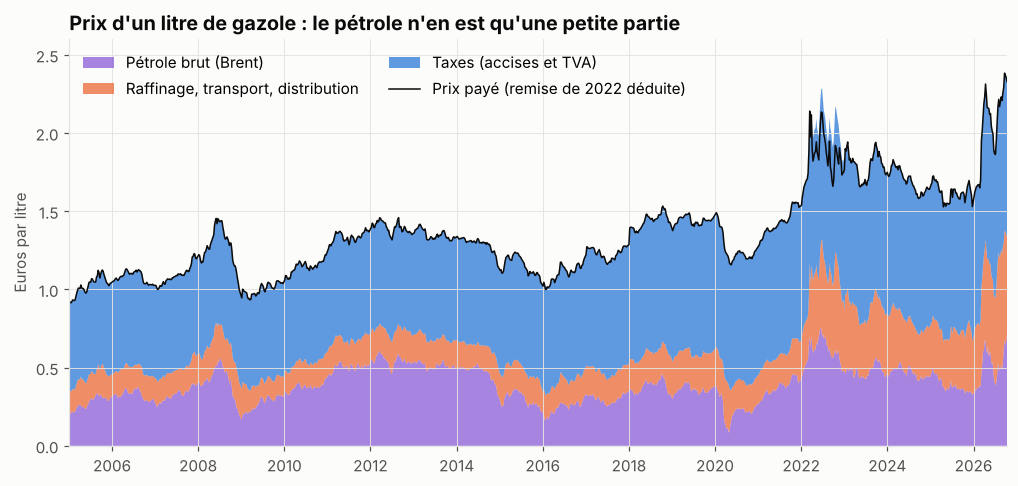

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = hebdo["date"]
couches = [hebdo["brent_eur_litre"], hebdo["marge_gazole"], hebdo["taxes_gazole"]]
ax.stackplot(x, *couches, colors=[VIOLET, ORANGE, BLEU], alpha=0.75, linewidth=0,
             labels=["Pétrole brut (Brent)", "Raffinage, transport, distribution", "Taxes (accises et TVA)"])
ax.plot(x, hebdo["gazole_ttc"], color=TEXTE, linewidth=1, label="Prix payé (remise de 2022 déduite)")
ax.set_ylabel("Euros par litre")
ax.set_ylim(0, 2.6)
ax.set_title("Prix d'un litre de gazole : le pétrole n'en est qu'une petite partie")
axe_annees(ax)
ax.legend(loc="upper left", frameon=False, ncols=2)
ax.set_xlim(x.min(), x.max())
sauver(fig, "11_decomposition_gazole")

En 2026, le Brent ne représente que **25 %** du prix moyen du gazole (0,51 € sur 2,04 €), contre 39 % en 2012, année où le baril valait pourtant un peu plus en euros (0,55 € par litre). Les taxes pèsent 46 % du prix, et la part « raffinage, transport, distribution » a grossi.

Entre 2025 et 2026 (moyennes de janvier à mi-octobre pour 2026), le gazole a pris 42 centimes : 12 viennent du Brent, 7 des taxes (la TVA augmente avec le prix) et **23 de l'écart entre le brut et la pompe**. Le pétrole n'explique donc qu'une petite partie de la flambée de 2026.

## 2. L'écart entre le baril et la pompe a doublé

On appelle ici **marge brute** l'écart entre le prix hors taxes et le coût du Brent. Ce n'est pas le bénéfice des distributeurs : elle paie le raffinage, le transport, le stockage, les biocarburants incorporés, les certificats d'économie d'énergie et la distribution. Mais son évolution dit où va l'argent.

Pointe de 2026 : 2026-08-31 0.748


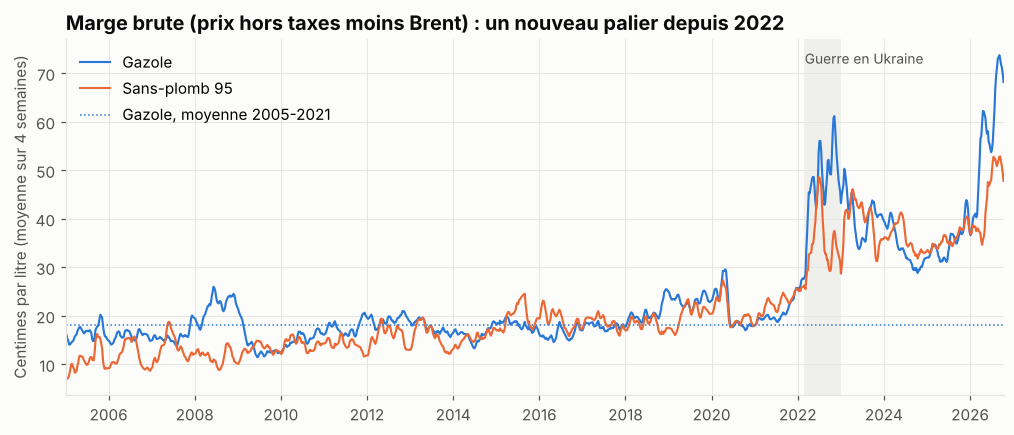

In [6]:
avant = hebdo.filter(pl.col("date").dt.year() <= 2021)
for carburant in ["gazole", "sp95"]:
    chiffres[f"marge_{carburant}_2005_2021"] = avant[f"marge_{carburant}"].mean()
    chiffres[f"marge_{carburant}_2023_2025"] = hebdo.filter(pl.col("date").dt.year().is_between(2023, 2025))[f"marge_{carburant}"].mean()
    chiffres[f"marge_{carburant}_2026"] = annee(2026, f"marge_{carburant}")  # janvier à mi-octobre
pointe = hebdo.filter(pl.col("date").dt.year() == 2026).sort("marge_gazole").row(-1, named=True)
chiffres["marge_gazole_pointe"] = pointe["marge_gazole"]
print("Pointe de 2026 :", pointe["date"], round(pointe["marge_gazole"], 3))
fig, ax = plt.subplots(figsize=(11, 4.2))
for carburant, couleur, nom in [("gazole", BLEU, "Gazole"), ("sp95", ORANGE, "Sans-plomb 95")]:
    lisse = hebdo.select("date", pl.col(f"marge_{carburant}").rolling_mean(4, min_samples=2))
    ax.plot(lisse["date"], lisse[f"marge_{carburant}"] * 100, color=couleur, linewidth=1.4, label=nom)
ax.axhline(chiffres["marge_gazole_2005_2021"] * 100, color=BLEU, linestyle=":", linewidth=1, label="Gazole, moyenne 2005-2021")
ax.axvspan(date(2022, 2, 24), date(2022, 12, 31), color=GRILLE, alpha=0.5, linewidth=0)
ax.annotate("Guerre en Ukraine", (date(2022, 3, 1), 72), color=TEXTE_2, fontsize=9)
ax.set_ylabel("Centimes par litre (moyenne sur 4 semaines)")
ax.set_title("Marge brute (prix hors taxes moins Brent) : un nouveau palier depuis 2022")
axe_annees(ax)
ax.set_xlim(hebdo["date"].min(), hebdo["date"].max())
ax.legend(loc="upper left", frameon=False)
sauver(fig, "12_marge_brute")

De 2005 à 2021, l'écart entre le Brent et le gazole hors taxes tourne autour de **18 centimes** par litre (16 pour le SP95). Depuis la guerre en Ukraine, il a changé de palier : 36 centimes en moyenne de 2023 à 2025 (37 pour le SP95), puis **58 centimes en 2026**, avec une pointe à 75 centimes à la fin de l'été.

Le changement de palier de 2022-2023 touche autant l'essence que le gazole, ce qui évoque des coûts communs aux deux (transport, biocarburants, certificats d'économie d'énergie, distribution) autant que le raffinage. En 2026 en revanche, le gazole décroche seul (44 centimes pour le SP95), ce qui pointe vers le raffinage du gazole : l'Europe en importait une partie de Russie avant l'embargo de 2023, et l'offre reste tendue à chaque crise. Le bulletin ne permet pas de séparer raffinage et distribution ; il faudrait pour cela les prix de gros (cotations de Rotterdam), qui ne sont pas en accès libre.

## 3. Fusée et plume : les prix montent-ils plus vite qu'ils ne baissent ?

Comparer les hausses et les baisses à l'œil ne suffit pas : le prix réagit avec retard, et il rattrape progressivement son niveau d'équilibre. On utilise donc le modèle de référence de la littérature (Borenstein, Cameron et Gilbert, 1997), un **modèle à correction d'erreur asymétrique** :

$$\Delta p_t = \sum_{i=0}^{4} \left(a^+_i \, \Delta c^+_{t-i} + a^-_i \, \Delta c^-_{t-i}\right) + \sum_{j=1}^{2} g_j \, \Delta p_{t-j} + \theta \left(p_{t-1} - \varphi \, c_{t-1} - f(t-1)\right) + \varepsilon_t$$

- $p$ est le prix hors taxes (remise de 2022 rajoutée), $c$ le Brent en euros par litre, $\Delta c^+$ et $\Delta c^-$ ses hausses et ses baisses d'une semaine à l'autre ;
- le dernier terme ramène le prix vers sa relation de long terme avec le Brent ($\varphi$ centimes par centime de Brent, plus une marge $f$ qui évolue lentement, estimée par une spline) ;
- s'il y a « fusée et plume », les $a^+$ sont plus grands que les $a^-$.

On estime d'abord la relation de long terme, puis la dynamique, par moindres carrés avec des écarts-types robustes à l'autocorrélation (Newey-West, 4 semaines). La période principale est **2005-2021** : depuis 2022, la marge change de palier et la relation de long terme du gazole se déforme (voir les variantes plus bas). Le code est dans `carburants.transmission`, testé sur des données simulées dont on connaît l'asymétrie.

In [7]:
PERIODE = (date(2005, 1, 1), date(2021, 12, 31))
HORIZON = 12

def serie(carburant, debut=PERIODE[0], fin=PERIODE[1]):
    return hebdo.filter(pl.col("date").is_between(debut, fin)).select(
        "date", prix=pl.col(f"{carburant}_ht") + pl.col("remise"), cout="brent_eur_litre"
    )

modeles = {carburant: transmission.estimer(serie(carburant)) for carburant in ["gazole", "sp95"]}
reponses = {carburant: modele.asymetrie(HORIZON) for carburant, modele in modeles.items()}
coefs = pl.DataFrame({
    "coefficient": modeles["gazole"].noms,
    **{f"{carburant}{suffixe}": [round(fonction(modele, nom), 3) for nom in modele.noms]
       for carburant, modele in modeles.items()
       for suffixe, fonction in [("", transmission.Transmission.coef), (" (é.-t.)", transmission.Transmission.ecart_type)]},
})
for carburant, modele in modeles.items():
    chiffres[f"phi_{carburant}"] = modele.phi
    chiffres[f"rappel_{carburant}"] = -modele.coef("rappel") * 100
    chiffres[f"wald_{carburant}"] = modele.test_wald()[1]
    chiffres[f"wald0_{carburant}"] = modele.test_wald([0])[1]
    chiffres[f"observations_{carburant}"] = modele.observations
    r = reponses[carburant]
    for h in [0, 1, 4, 8]:
        for cle in ["hausse", "baisse", "ecart", "ecart_bas", "ecart_haut"]:
            chiffres[f"{cle}_{carburant}_{h}"] = r[cle][h]
    print(f"{carburant} : {modele.observations} semaines, R² = {modele.r2:.2f}, phi = {modele.phi:.2f}, "
          f"test d'égalité des sommes p = {chiffres[f'wald_{carburant}']:.3f}, au retard 0 p = {chiffres[f'wald0_{carburant}']:.3f}")
coefs

gazole : 659 semaines, R² = 0.68, phi = 1.09, test d'égalité des sommes p = 0.000, au retard 0 p = 0.001
sp95 : 659 semaines, R² = 0.55, phi = 0.97, test d'égalité des sommes p = 0.388, au retard 0 p = 0.558


coefficient,gazole,gazole (é.-t.),sp95,sp95 (é.-t.)
str,f64,f64,f64,f64
"""constante""",-0.002,0.001,0.0,0.001
"""hausse_0""",0.645,0.044,0.497,0.054
"""baisse_0""",0.403,0.048,0.444,0.055
"""hausse_1""",0.402,0.058,0.325,0.056
"""baisse_1""",0.233,0.059,0.328,0.05
"""hausse_2""",-0.033,0.055,0.032,0.052
"""baisse_2""",-0.04,0.044,0.065,0.053
"""hausse_3""",0.012,0.04,-0.019,0.053
"""baisse_3""",-0.045,0.056,0.104,0.062


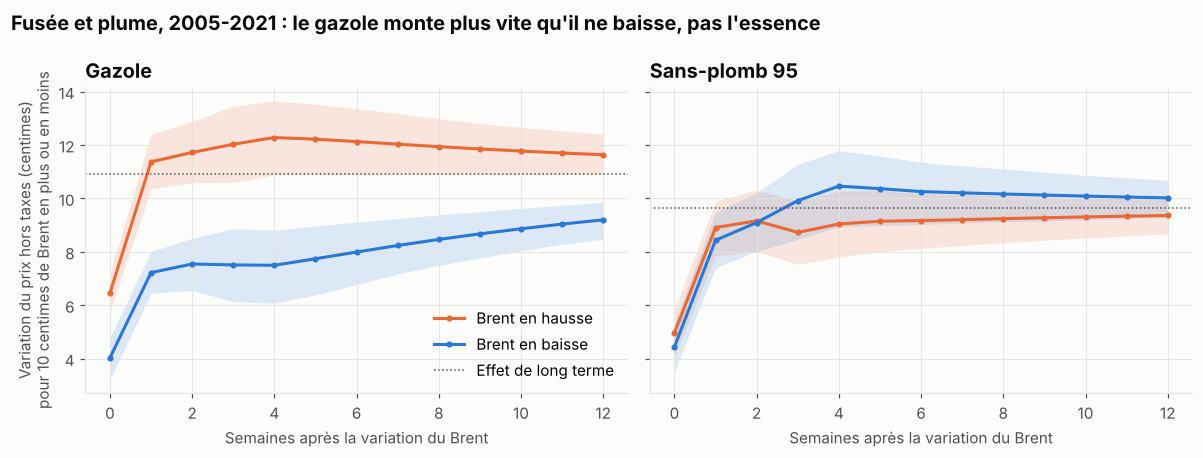

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
semaines = np.arange(HORIZON + 1)
for ax, (carburant, nom) in zip(axes, [("gazole", "Gazole"), ("sp95", "Sans-plomb 95")]):
    r = reponses[carburant]
    for sens, couleur, libelle in [("hausse", ORANGE, "Brent en hausse"), ("baisse", BLEU, "Brent en baisse")]:
        ax.fill_between(semaines, r[f"{sens}_bas"] * 10, r[f"{sens}_haut"] * 10, color=couleur, alpha=0.15, linewidth=0)
        ax.plot(semaines, r[sens] * 10, color=couleur, linewidth=2, marker="o", markersize=3, label=libelle)
    ax.axhline(modeles[carburant].phi * 10, color=TEXTE_2, linestyle=":", linewidth=1, label="Effet de long terme")
    ax.set_title(nom)
    ax.set_xlabel("Semaines après la variation du Brent")
    ax.set_xticks(range(0, HORIZON + 1, 2))
axes[0].set_ylabel("Variation du prix hors taxes (centimes)\npour 10 centimes de Brent en plus ou en moins")
axes[0].legend(loc="lower right", frameon=False)
fig.suptitle("Fusée et plume, 2005-2021 : le gazole monte plus vite qu'il ne baisse, pas l'essence",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.tight_layout()
sauver(fig, "13_fusee_et_plume")

**Le gazole monte en fusée et redescend en plume.** Quand le Brent gagne 10 centimes par litre, le gazole hors taxes prend 11,4 centimes en une semaine ; quand le Brent en perd 10, le gazole n'en rend que 7,2. L'écart, 4,1 centimes (intervalle à 90 % : 2,7 à 5,6), est encore de 4,8 centimes un mois après (2,6 à 7,1). Avec la TVA, il faut le multiplier par 1,2 à la pompe. Le test d'égalité des réactions cumulées rejette nettement la symétrie (p = 0,0001).

**Le sans-plomb 95 est symétrique** : 8,9 centimes à la hausse contre 8,4 à la baisse après une semaine, un écart qui n'est pas significatif (intervalle à 90 % : −1,4 à 2,2 ; p = 0,39).

À long terme, tout finit par passer : un centime de Brent devient environ 1,09 centime de gazole hors taxes (0,97 pour le SP95). Mais l'ajustement est lent : chaque semaine, le prix comble environ 7 % de l'écart restant à son équilibre. L'asymétrie porte donc sur des semaines, pas sur des jours, et elle coûte surtout lors des retournements rapides du pétrole.

## 4. Les résultats tiennent-ils ?

On fait varier un choix à la fois : la période (avec 2022-2026, avec ou sans l'année 2022), le nombre de semaines de retard du Brent, et la souplesse de la marge de long terme (constante, ou spline à 8 degrés de liberté).

In [9]:
VARIANTES = [
    ("Référence (2005-2021, 4 retards, spline 4)", {}),
    ("2005-2026", {"fin": date(2026, 12, 31)}),
    ("2005-2026 sans 2022", {"fin": date(2026, 12, 31), "exclure": (date(2022, 3, 1), date(2023, 1, 31))}),
    ("2 semaines de retard", {"retards_cout": 2}),
    ("6 semaines de retard", {"retards_cout": 6}),
    ("Marge de long terme constante", {"tendance_df": 0}),
    ("Spline à 8 degrés de liberté", {"tendance_df": 8}),
]
lignes = []
for nom, options in VARIANTES:
    options = dict(options)
    fin = options.pop("fin", PERIODE[1])
    for carburant in ["gazole", "sp95"]:
        modele = transmission.estimer(serie(carburant, fin=fin), **options)
        r = modele.asymetrie(HORIZON)
        lignes.append({"variante": nom, "carburant": carburant, "semaines": modele.observations, "phi": round(modele.phi, 2),
                       **{f"écart S{h} (c)": f"{r['ecart'][h] * 10:+.1f} [{r['ecart_bas'][h] * 10:+.1f} ; {r['ecart_haut'][h] * 10:+.1f}]" for h in [1, 4]},
                       "p (Wald)": round(modele.test_wald()[1], 3)})
        cle = "gazole" if carburant == "gazole" else "sp95"
        chiffres.setdefault(f"robustesse_min_ecart1_{cle}", np.inf)
        chiffres.setdefault(f"robustesse_min_bas1_{cle}", np.inf)
        chiffres[f"robustesse_min_ecart1_{cle}"] = min(chiffres[f"robustesse_min_ecart1_{cle}"], r["ecart"][1])
        chiffres[f"robustesse_min_bas1_{cle}"] = min(chiffres[f"robustesse_min_bas1_{cle}"], r["ecart_bas"][1])
        if nom == "2005-2026":
            chiffres[f"phi_{cle}_2026"] = modele.phi
        if nom == "2005-2026 sans 2022":
            chiffres[f"wald_{cle}_sans_2022"] = modele.test_wald()[1]
robustesse = pl.DataFrame(lignes)
robustesse

variante,carburant,semaines,phi,écart S1 (c),écart S4 (c),p (Wald)
str,str,i64,f64,str,str,f64
"""Référence (2005-2021, 4 retard…","""gazole""",659,1.09,"""+4.1 [+2.7 ; +5.6]""","""+4.8 [+2.6 ; +7.1]""",0.0
"""Référence (2005-2021, 4 retard…","""sp95""",659,0.97,"""+0.5 [-1.4 ; +2.2]""","""-1.4 [-3.6 ; +0.8]""",0.388
"""2005-2026""","""gazole""",898,1.31,"""+6.3 [+2.5 ; +9.8]""","""+5.0 [+1.4 ; +8.6]""",0.017
"""2005-2026""","""sp95""",898,1.1,"""+2.4 [-0.3 ; +4.9]""","""+0.5 [-1.9 ; +2.9]""",0.638
"""2005-2026 sans 2022""","""gazole""",851,1.31,"""+3.5 [+0.7 ; +6.2]""","""+2.9 [-1.1 ; +6.8]""",0.21
"""2005-2026 sans 2022""","""sp95""",851,1.1,"""+0.2 [-1.6 ; +1.8]""","""-0.2 [-2.6 ; +2.2]""",0.935
"""2 semaines de retard""","""gazole""",731,1.09,"""+3.3 [+1.5 ; +5.1]""","""+3.0 [+1.2 ; +4.8]""",0.006
"""2 semaines de retard""","""sp95""",731,0.97,"""-0.3 [-2.1 ; +1.7]""","""-0.9 [-2.6 ; +0.7]""",0.402
"""6 semaines de retard""","""gazole""",587,1.09,"""+4.5 [+2.7 ; +6.2]""","""+4.9 [+2.6 ; +7.5]""",0.0


Pour le gazole, l'écart après une semaine reste positif dans toutes les variantes (au moins 3,3 centimes pour 10 centimes de Brent, 4,1 dans la référence), et son intervalle à 90 % exclut zéro dans chacune (borne basse la plus faible : 0,7 centime pour 10 centimes de Brent). Le résultat est le moins net quand on ajoute 2022-2026 en retirant l'année 2022 : l'écart après un mois n'est plus significatif et le test sur la somme des réactions ne rejette plus la symétrie (p = 0,21). Pour le SP95, aucune variante ne trouve d'asymétrie significative.

Sur 2005-2026, la relation de long terme du gazole se déforme : un centime de Brent devient 1,31 centime de gazole hors taxes, contre 1,09 avant 2022. Depuis la guerre en Ukraine, quand le pétrole monte, l'écart entre le brut et le gazole monte avec lui.

## 5. La crise de 2026, semaine par semaine

In [10]:
crise = hebdo.filter(pl.col("date") >= date(2025, 12, 1))
DEBUT_HAUSSE, SOMMET, CREUX = date(2026, 3, 2), date(2026, 4, 13), date(2026, 7, 6)
def le(jour, colonne):
    return crise.filter(date=jour)[colonne].item()
for phase, (debut, fin) in {"hausse": (DEBUT_HAUSSE, SOMMET), "baisse": (SOMMET, CREUX)}.items():
    chiffres[f"crise_{phase}_brent"] = le(fin, "brent_eur_litre") - le(debut, "brent_eur_litre")
    chiffres[f"crise_{phase}_gazole"] = le(fin, "gazole_ht") - le(debut, "gazole_ht")
    chiffres[f"crise_{phase}_semaines"] = (fin - debut).days / 7
for jour, nom in [(DEBUT_HAUSSE, "debut"), (SOMMET, "sommet"), (CREUX, "creux")]:
    chiffres[f"crise_marge_{nom}"] = le(jour, "marge_gazole")
chiffres["crise_marge_fin"] = crise["marge_gazole"][-1]
crise.select("date", "brent_usd_baril", "brent_eur_litre", "gazole_ht", "marge_gazole").with_columns(pl.exclude("date").round(3))

date,brent_usd_baril,brent_eur_litre,gazole_ht,marge_gazole
date,f64,f64,f64,f64
2025-12-01,64.425,0.35,0.775,0.425
2025-12-08,63.982,0.346,0.751,0.405
2025-12-15,62.604,0.337,0.725,0.388
2025-12-22,60.826,0.326,0.666,0.34
2025-12-29,63.207,0.338,0.691,0.353
2026-01-05,62.182,0.333,0.717,0.384
2026-01-12,62.926,0.339,0.745,0.406
2026-01-19,66.996,0.362,0.759,0.397
2026-01-26,67.005,0.359,0.775,0.416


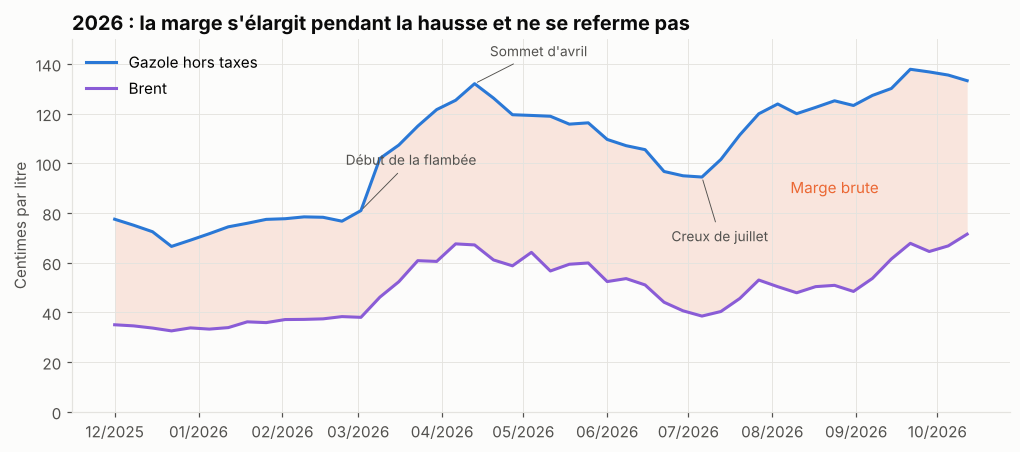

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.fill_between(crise["date"], crise["brent_eur_litre"] * 100, crise["gazole_ht"] * 100, color=ORANGE, alpha=0.15, linewidth=0)
ax.plot(crise["date"], crise["gazole_ht"] * 100, color=BLEU, linewidth=2, label="Gazole hors taxes")
ax.plot(crise["date"], crise["brent_eur_litre"] * 100, color=VIOLET, linewidth=2, label="Brent")
for jour, texte, decalage in [(DEBUT_HAUSSE, "Début de la flambée", (-10, 30)), (SOMMET, "Sommet d'avril", (10, 18)), (CREUX, "Creux de juillet", (-20, -42))]:
    ax.annotate(texte, (jour, le(jour, "gazole_ht") * 100), xytext=decalage, textcoords="offset points", fontsize=9,
                color=TEXTE_2, arrowprops={"arrowstyle": "-", "color": TEXTE_2, "linewidth": 0.6})
milieu = crise.filter(date=date(2026, 8, 24)).row(0, named=True)
ax.annotate("Marge brute", (milieu["date"], (milieu["brent_eur_litre"] + milieu["gazole_ht"]) / 2 * 100), ha="center", color=ORANGE, fontsize=10)
ax.set_ylabel("Centimes par litre")
ax.set_ylim(0, 150)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("2026 : la marge s'élargit pendant la hausse et ne se referme pas")
ax.legend(loc="upper left", frameon=False)
sauver(fig, "14_crise_2026")

Du début mars à la mi-avril (6 semaines), le Brent prend 29 centimes par litre et le gazole hors taxes **51**. De la mi-avril au début juillet (12 semaines), le Brent rend tout ce qu'il avait pris (−29 centimes), le gazole seulement −38. La marge brute passe ainsi de 43 centimes avant la crise à 65 au sommet, n'est qu'à 56 au creux, puis remonte jusqu'à 75 à la fin de l'été (62 à la mi-octobre).

C'est l'effet fusée et plume, amplifié : une partie de la hausse ne vient pas du brut mais du raffinage du gazole, tendu en Europe. Le bulletin ne permet pas de dire quelle part revient aux raffineurs et quelle part aux distributeurs.

## Limites

- **Le Brent n'est pas le coût d'achat des stations.** Celles-ci achètent du gazole et de l'essence raffinés, dont le prix de gros (Rotterdam) peut s'écarter du brut. L'asymétrie mesurée ici couvre toute la chaîne, du baril à la pompe ; on ne peut pas dire si elle naît au raffinage ou à la distribution.
- **Moyenne nationale** : le bulletin est une moyenne pondérée. Certaines stations répercutent sans doute plus vite que d'autres ; c'est l'objet de l'étape suivante, station par station.
- **Données hebdomadaires** : la dynamique d'un jour à l'autre est invisible, et quelques semaines manquent au bulletin (surtout les premières années).
- **Remise de TotalEnergies en 2022** : non corrigée, elle abaisse la marge moyenne de septembre à décembre 2022 ; la variante sans 2022 montre qu'elle ne change pas les conclusions.
- **Euros courants** : les marges ne sont pas corrigées de l'inflation, qui explique une partie de leur lente hausse avant 2022, mais pas le saut de 2022.

## À retenir

- **Le pétrole ne pèse que 25 % du prix du gazole en 2026**, contre 39 % en 2012 à baril comparable. Les taxes en font 46 %.
- **L'écart entre le baril et la pompe a changé de palier** : environ 18 centimes par litre de gazole jusqu'en 2021, 36 de 2023 à 2025 et 58 en 2026. Il explique la plus grande partie de la hausse de 2026.
- **Fusée et plume, oui pour le gazole** : sur 2005-2021, pour 10 centimes de Brent, le gazole hors taxes monte de 11,4 centimes en une semaine mais ne baisse que de 7,2. Cet écart à une semaine se retrouve dans toutes les variantes testées.
- **Non pour l'essence** : la réaction du SP95 est symétrique.
- Prochaine étape : passer de la moyenne nationale aux stations, et mesurer ce qui fait varier les prix de l'une à l'autre (concurrence locale, enseigne, autoroute).

In [12]:
# Vérification : les chiffres cités dans le texte ci-dessus correspondent aux calculs de ce notebook.
# Ils sont aussi exportés pour le site.
CHIFFRES_JSON = Path('../rapports/chiffres_03.json')
CHIFFRES_JSON.write_text(json.dumps({k: round(float(v), 6) for k, v in sorted(chiffres.items())}, indent=1) + "\n")
CITES = {
 "semaines_comparees": [
  982.0,
  0.5
 ],
 "correlation_gazole": [
  0.994755,
  0.0005
 ],
 "correlation_sp95": [
  0.995627,
  0.0005
 ],
 "ecart_stations_gazole": [
  0.019527,
  0.0005
 ],
 "ecart_stations_sp95": [
  0.021797,
  0.0005
 ],
 "ecart_stations_gazole_p05": [
  -0.012571,
  0.0005
 ],
 "ecart_stations_gazole_p95": [
  0.056188,
  0.0005
 ],
 "part_brent_2026": [
  25.091402,
  0.5
 ],
 "brent_2026": [
  0.51109,
  0.005
 ],
 "ttc_2026": [
  2.036913,
  0.005
 ],
 "part_brent_2012": [
  39.093686,
  0.5
 ],
 "brent_2012": [
  0.54609,
  0.005
 ],
 "part_taxes_2026": [
  46.491215,
  0.5
 ],
 "hausse_2026_ttc": [
  0.418351,
  0.005
 ],
 "hausse_2026_brent_eur_litre": [
  0.124186,
  0.005
 ],
 "hausse_2026_taxes_gazole": [
  0.068024,
  0.005
 ],
 "hausse_2026_marge_gazole": [
  0.226141,
  0.005
 ],
 "marge_gazole_2005_2021": [
  0.18076,
  0.005
 ],
 "marge_sp95_2005_2021": [
  0.162764,
  0.005
 ],
 "marge_gazole_2023_2025": [
  0.364973,
  0.005
 ],
 "marge_sp95_2023_2025": [
  0.371168,
  0.005
 ],
 "marge_gazole_2026": [
  0.578837,
  0.005
 ],
 "marge_gazole_pointe": [
  0.748431,
  0.005
 ],
 "marge_sp95_2026": [
  0.444381,
  0.005
 ],
 "hausse_gazole_1": [
  1.137041,
  0.005
 ],
 "baisse_gazole_1": [
  0.722124,
  0.005
 ],
 "ecart_gazole_1": [
  0.414918,
  0.005
 ],
 "ecart_bas_gazole_1": [
  0.272513,
  0.005
 ],
 "ecart_haut_gazole_1": [
  0.563969,
  0.005
 ],
 "ecart_gazole_4": [
  0.478357,
  0.005
 ],
 "ecart_bas_gazole_4": [
  0.255745,
  0.005
 ],
 "ecart_haut_gazole_4": [
  0.705284,
  0.005
 ],
 "wald_gazole": [
  0.000117,
  5e-05
 ],
 "hausse_sp95_1": [
  0.890973,
  0.005
 ],
 "baisse_sp95_1": [
  0.84335,
  0.005
 ],
 "ecart_bas_sp95_1": [
  -0.135992,
  0.005
 ],
 "ecart_haut_sp95_1": [
  0.220183,
  0.005
 ],
 "wald_sp95": [
  0.387872,
  0.005
 ],
 "phi_gazole": [
  1.092161,
  0.005
 ],
 "phi_sp95": [
  0.965331,
  0.005
 ],
 "rappel_gazole": [
  7.233356,
  0.5
 ],
 "robustesse_min_ecart1_gazole": [
  0.332241,
  0.005
 ],
 "robustesse_min_bas1_gazole": [
  0.070154,
  0.005
 ],
 "wald_gazole_sans_2022": [
  0.209578,
  0.005
 ],
 "phi_gazole_2026": [
  1.312727,
  0.005
 ],
 "crise_hausse_semaines": [
  6.0,
  0.5
 ],
 "crise_hausse_brent": [
  0.291455,
  0.005
 ],
 "crise_hausse_gazole": [
  0.5108,
  0.005
 ],
 "crise_baisse_semaines": [
  12.0,
  0.5
 ],
 "crise_baisse_brent": [
  -0.286392,
  0.005
 ],
 "crise_baisse_gazole": [
  -0.375758,
  0.005
 ],
 "crise_marge_debut": [
  0.429667,
  0.005
 ],
 "crise_marge_sommet": [
  0.649012,
  0.005
 ],
 "crise_marge_creux": [
  0.559646,
  0.005
 ],
 "crise_marge_fin": [
  0.617615,
  0.005
 ]
}
ecarts_cites = {cle: (valeur, chiffres.get(cle)) for cle, (valeur, tolerance) in CITES.items()
                if chiffres.get(cle) is None or not abs(chiffres[cle] - valeur) <= tolerance}
assert not ecarts_cites, f"Chiffres du texte à mettre à jour : {ecarts_cites}"
print(f"{len(CITES)} chiffres cités, tous conformes aux calculs")

55 chiffres cités, tous conformes aux calculs
